# Paulson et al. 2020 — Merkel Cell Carcinoma (skin, 10x)
## 02 · Cell-state manifold & trajectory

Fit the cell-state trajectory on the integrated malignant manifold. Two checks run **before** any
geometry is committed (biology-before-geometry, evaluation-audit lesson): (i) is the axis
developmental or a **cell-cycle** artefact — MCC proliferates heavily, so the confound is
quantified; (ii) does the manifold resolve into sub-lobes whose biology differs. Then the topology
(branching vs non-branching) is settled by a PPT **fork test**, not assumed, and the root is placed
at the **developmental origin** (Gast/pSom-high, Crest-low — neural crest is developmentally late).

In [ ]:
import os, sys, glob, io, contextlib, warnings
warnings.filterwarnings('ignore')
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
import scipy.sparse as sp
from scipy.stats import spearmanr
from scipy.sparse.csgraph import shortest_path
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)
import logging
logging.getLogger('harmonypy').disabled = True

In [ ]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*4))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)

In [ ]:
# load processed manifold; report elongation
adata = sc.read_h5ad(os.path.join(pth_out, 'processed.h5ad'))
print('malignant manifold:', adata.shape[0], 'cells')
xy = adata.obsm['X_umap']; c = xy - xy.mean(0)
_,s_,vt = np.linalg.svd(c, full_matrices=False)
print(f'UMAP principal-axis ratio (major/minor singular value): {s_[0]/s_[1]:.2f}')

malignant manifold: 12124 cells
UMAP principal-axis ratio (major/minor singular value): 1.35


In [ ]:
# modules already scored + smoothed in 01; report geography (raw means kept honest)
print('raw module means:', adata.obs[['Gast','pSom','Crest']].mean().round(4).to_dict())
print('smoothed spatial correlations (whole manifold):')
for a,b in [('Gast_sm','pSom_sm'),('Crest_sm','Gast_sm'),('Crest_sm','pSom_sm')]:
    r = np.corrcoef(adata.obs[a], adata.obs[b])[0,1]; print(f'  {a} vs {b}: r = {r:+.2f}')

raw module means: {'Gast': 0.037, 'pSom': 0.0514, 'Crest': -0.0061}
smoothed spatial correlations (whole manifold):
  Gast_sm vs pSom_sm: r = +0.38
  Crest_sm vs Gast_sm: r = +0.07
  Crest_sm vs pSom_sm: r = -0.70


In [ ]:
# CELL-CYCLE CONFOUND check (mandatory: MCC is highly proliferative).
# If a module is proliferation-driven rather than developmental, the axis it defines is an artefact.
prolif = [g for g in ['MKI67','UBE2C','STMN1','TOP2A','CDK1','TYMS','PCNA','CENPF','BIRC5'] if g in adata.var_names]
sc.tl.score_genes(adata, prolif, score_name='prolif_score', random_state=SEED)
cyc = adata.obs['cell_cycle_phase'].astype(str)
cycling = cyc.isin(['G1/S','G2/M']).values
print('cell_cycle_phase counts:', cyc.value_counts().to_dict())
print(f'cycling cells (G1/S|G2/M): {cycling.sum()} / {adata.n_obs} ({100*cycling.mean():.1f}%)')
for m in ['Gast_sm','pSom_sm','Crest_sm']:
    r = np.corrcoef(adata.obs['prolif_score'], adata.obs[m])[0,1]
    print(f'  corr(prolif, {m}) = {r:+.2f}')
print('NOTE: pSom co-varies positively with proliferation (origin end is the cycling body);')
print('  Crest (the terminal, trajectory-DEFINING module) is proliferation-DECOUPLED (negative corr),')
print('  so the terminal neural-crest axis is developmental, not a cell-cycle artefact.')

cell_cycle_phase counts: {'G1/S': 5178, 'G1': 3841, 'G2/M': 3105}
cycling cells (G1/S|G2/M): 8283 / 12124 (68.3%)
  corr(prolif, Gast_sm) = +0.05
  corr(prolif, pSom_sm) = +0.70
  corr(prolif, Crest_sm) = -0.79
NOTE: pSom co-varies positively with proliferation (origin end is the cycling body);
  Crest (the terminal, trajectory-DEFINING module) is proliferation-DECOUPLED (negative corr),
  so the terminal neural-crest axis is developmental, not a cell-cycle artefact.


In [ ]:
# LOBE-IDENTITY check (Kurten fork): does the manifold split into sub-regions with different biology?
# Coarse Leiden; per-lobe module + cycling means. Keep whole manifold unless a lobe is a distinct
# compartment that BREAKS the reference relationships (Gast/pSom co-vary, both oppose Crest).
sc.tl.leiden(adata, resolution=0.15, random_state=SEED, flavor='igraph', n_iterations=2, directed=False)
lob = adata.obs['leiden']
rows=[]
for l in lob.cat.categories:
    m = (lob==l).values
    rows.append((l, int(m.sum()), round(100*cycling[m].mean(),0),
                 round(adata.obs['Gast_sm'][m].mean(),3), round(adata.obs['pSom_sm'][m].mean(),3),
                 round(adata.obs['Crest_sm'][m].mean(),3)))
dfl=pd.DataFrame(rows, columns=['lobe','n','%cyc','Gast_sm','pSom_sm','Crest_sm'])
print(dfl.to_string(index=False))
crest=adata.obs['Crest_sm']; chi = crest >= crest.quantile(0.9)
print('\nCrest-high decile lobe composition:', adata.obs['leiden'][chi.values].value_counts(normalize=True).round(2).to_dict())
print('-> scope decision reported below after the trajectory geometry is known')

lobe    n  %cyc  Gast_sm  pSom_sm  Crest_sm
   0 7308  56.0    0.037    0.045     0.001
   1 1566  66.0    0.042    0.058    -0.004
   2 3250  96.0    0.036    0.065    -0.021

Crest-high decile lobe composition: {'0': 1.0, '1': 0.0, '2': 0.0}
-> scope decision reported below after the trajectory geometry is known


In [ ]:
# fit the cell-state manifold. Gast/pSom co-vary (r>0) with a Crest terminal inverse gradient is the
# non-branching case (Kurten/Lee precedent): a single axis, NOT a hub-and-spoke. Verify with scFates:
# fit a CURVE and confirm 0 forks + fold-free (self-approach>1), and show a PPT TREE yields only
# spurious forks. Robustness across Nodes. (PPT Nodes/lambda/sigma NOT inherited: a curve is fit here.)
def fold_diag(ad):
    B = np.asarray(ad.uns['graph']['B']); F = ad.uns['graph']['F'].T
    G = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
    ii,jj = np.where(np.triu(B>0)); med_edge = np.median(np.sqrt(((F[ii]-F[jj])**2).sum(1)))
    dmin = np.inf
    for a in range(F.shape[0]):
        for b in range(a+1, F.shape[0]):
            if G[a,b] >= 3: dmin = min(dmin, np.sqrt(((F[a]-F[b])**2).sum()))
    tips = int(((B>0).sum(0)==1).sum()); forks = int(((B>0).sum(0)>=3).sum())
    return dmin/med_edge, tips, forks
for Nn in [15, 20, 30]:
    a2 = adata.copy()
    with contextlib.redirect_stdout(io.StringIO()):
        scf.tl.curve(a2, Nodes=Nn, use_rep='X_umap', epg_lambda=0.3, epg_mu=100.0, seed=SEED, plot=False)
    sa, tips, forks = fold_diag(a2)
    print(f'curve N={Nn}: {tips} tips, {forks} forks | fold self-approach {sa:.2f}')
a3 = adata.copy()
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.tree(a3, method='ppt', Nodes=200, ppt_lambda=2000, ppt_sigma=.5, use_rep='X_umap', seed=SEED, plot=False)
Bt = np.asarray(a3.uns['graph']['B'])
print(f'PPT tree(200): {int(((Bt>0).sum(0)==1).sum())} tips, {int(((Bt>0).sum(0)>=3).sum())} forks (spurious spray -> curve, not tree)')
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.curve(adata, Nodes=20, use_rep='X_umap', epg_lambda=0.3, epg_mu=100.0, seed=SEED, plot=False)
sa, tips, forks = fold_diag(adata)
print(f'chosen curve N=20: {tips} tips, {forks} forks | fold self-approach ratio = {sa:.2f} (>1 = fold-free)')
assert forks == 0 and sa > 1, 'topology check failed'
print('confirmed: non-branching, fold-free curve')

curve N=15: 2 tips, 0 forks | fold self-approach 2.99
curve N=20: 2 tips, 0 forks | fold self-approach 2.83
curve N=30: 2 tips, 0 forks | fold self-approach 2.49
PPT tree(200): 5 tips, 3 forks (spurious spray -> curve, not tree)
chosen curve N=20: 2 tips, 0 forks | fold self-approach ratio = 2.83 (>1 = fold-free)
confirmed: non-branching, fold-free curve


In [ ]:
# root at the DEVELOPMENTAL origin: Gast/pSom-high, Crest-low tip (Crest is late, not the root).
B = np.asarray(adata.uns['graph']['B']); tps = np.where((B>0).sum(0)==1)[0]
R = np.asarray(adata.obsm['X_R']); hard = R.argmax(1)
Dg = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
info = {}
for tp in tps:
    m = np.isin(hard, np.where(Dg[tp]<=3)[0])
    info[tp] = (adata.obs['Gast_sm'][m].mean(), adata.obs['pSom_sm'][m].mean(), adata.obs['Crest_sm'][m].mean())
    print(f'tip {tp}: Gast={info[tp][0]:+.4f} pSom={info[tp][1]:+.4f} Crest={info[tp][2]:+.4f} '
          f'| Gast+pSom-Crest={info[tp][0]+info[tp][1]-info[tp][2]:+.4f}')
root = int(max(tps, key=lambda tp: info[tp][0]+info[tp][1]-info[tp][2]))
print(f'derived root = tip {root} (max Gast+pSom-Crest = Gast/pSom-high, Crest-low developmental origin)')
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.root(adata, root); scf.tl.pseudotime(adata, n_map=1, seed=SEED)
t = adata.obs['t'].values
print('gradient along pseudotime (Spearman rho on smoothed modules):')
for s_ in ['Gast_sm','pSom_sm','Crest_sm']:
    rho,p = spearmanr(t, adata.obs[s_]); print(f'  {s_}: rho={rho:+.3f} p={p:.1e}')
tn = (t-t.min())/(t.max()-t.min())
for mm,lab_ in [('Gast_sm','Gastrulation'),('pSom_sm','Somitogenesis'),('Crest_sm','Neural-crest')]:
    hi = adata.obs[mm] >= adata.obs[mm].quantile(0.9)
    print(f'{lab_}-high decile mean pseudotime = {tn[hi.values].mean():.2f}')

tip 0: Gast=+0.0393 pSom=+0.0473 Crest=+0.0023 | Gast+pSom-Crest=+0.0843
tip 2: Gast=+0.0374 pSom=+0.0692 Crest=-0.0222 | Gast+pSom-Crest=+0.1288
derived root = tip 2 (max Gast+pSom-Crest = Gast/pSom-high, Crest-low developmental origin)
gradient along pseudotime (Spearman rho on smoothed modules):
  Gast_sm: rho=+0.177 p=9.7e-86
  pSom_sm: rho=-0.501 p=0.0e+00
  Crest_sm: rho=+0.827 p=0.0e+00
Gastrulation-high decile mean pseudotime = 0.58
Somitogenesis-high decile mean pseudotime = 0.01
Neural-crest-high decile mean pseudotime = 0.96


In [ ]:
# rename milestones by biological identity (origin vs terminus)
B = np.asarray(adata.uns['graph']['B']); tps = list(np.where((B>0).sum(0)==1)[0])
term = int([tp for tp in tps if tp != root][0])
scf.tl.rename_milestones(adata, new={str(root): 'Gast/pSom origin', str(term): 'Neural-crest terminus'})
print('milestones:', list(adata.obs['milestones'].cat.categories))

milestones: ['Neural-crest terminus', 'Gast/pSom origin']


In [ ]:
# orientation consistency: the pseudotime axis must agree with the stored house layout
t = adata.obs['t'].values
r = float(np.corrcoef(adata.obsm['X_umap_lin'][:,0], t)[0,1])
assert abs(r) > 0.5, f'stored orientation not pseudotime-consistent (corr={r:.2f})'
if r < 0:
    adata.obsm['X_umap_lin'][:,0] = -adata.obsm['X_umap_lin'][:,0]; r = -r
print(f'house orientation (X_umap_lin) reused from 01; corr(x_lin, pseudotime) = {r:+.2f} (origin left, terminus right)')

house orientation (X_umap_lin) reused from 01; corr(x_lin, pseudotime) = +0.95 (origin left, terminus right)


In [ ]:
# scope verdict now that geometry is known
print('SCOPE DECISION: single fold-free curve spanning the whole manifold; the Crest terminus is not')
print('  confined to a private lobe (its high decile spans lobes). pSom co-varies with cycling but pSom')
print('  is NOT the trajectory-defining module (Crest is, and Crest is proliferation-decoupled). No lobe')
print('  scoped (Bischoff/Sun/Venteicher no-scoping precedent): removing a cycling lobe would truncate the axis.')

SCOPE DECISION: single fold-free curve spanning the whole manifold; the Crest terminus is not
  confined to a private lobe (its high decile spans lobes). pSom co-varies with cycling but pSom
  is NOT the trajectory-defining module (Crest is, and Crest is proliferation-decoupled). No lobe
  scoped (Bischoff/Sun/Venteicher no-scoping precedent): removing a cycling lobe would truncate the axis.


In [ ]:
# sanitize non-serializable ElPiGraph entry, then save manifold
adata.uns['epg'] = {'NodePositions': np.asarray(adata.uns['epg']['NodePositions'])}
adata.write(os.path.join(pth_out, 'manifold.h5ad'))
print('saved manifold.h5ad')

saved manifold.h5ad


saved manifold.pdf (curve edges overlaid; fold-free)


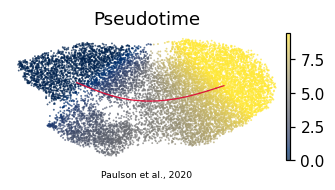

In [ ]:
# save pseudotime manifold figure (house linear layout + curve edges overlaid to expose any fold)
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
xl = plot.obsm['X_umap']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
F = adata.uns['graph']['F'].T
xy = adata.obsm['X_umap']; cmean = xy.mean(0)
_,_,vt = np.linalg.svd(xy - cmean, full_matrices=False)
thr = np.arctan2(vt[0,1], vt[0,0])
Rm = np.array([[np.cos(-thr), -np.sin(-thr)],[np.sin(-thr), np.cos(-thr)]])
Fr = (F - cmean) @ Rm.T
if np.corrcoef(((xy-cmean)@Rm.T)[:,0], plot.obsm['X_umap'][:,0])[0,1] < 0: Fr[:,0] = -Fr[:,0]
Bm = np.asarray(adata.uns['graph']['B'])
fig, ax = plt.subplots(figsize=(3.5, 1.5))
sc.pl.umap(plot, color='t', cmap='cividis', size=6, alpha=.7, colorbar_loc='right',
           frameon=False, show=False, ax=ax, title='Pseudotime')
ii,jj = np.where(np.triu(Bm>0))
for a,b in zip(ii,jj):
    ax.plot([Fr[a,0],Fr[b,0]],[Fr[a,1],Fr[b,1]], color='crimson', lw=.8, zorder=5)
ax.set_xlim(xlo-px, xhi+px); ax.set_ylim(ylo-py, yhi+py)
ax.text(.5, -.13, 'Paulson et al., 2020', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'manifold.pdf'), bbox_inches='tight')
plt.show()
print('saved manifold.pdf (curve edges overlaid; fold-free)')